# BƯỚC 1 & 2: NẠP ẢNH, KHÔNG GIAN MÀU VÀ TIỀN XỬ LÝ (TASK 1 & TASK 2)

Thực hành đọc ảnh đầu vào, kiểm định cấu trúc RGB `uint8`, chuyển đổi sang các không gian màu `HSV` và `CIE LAB`, thu nhỏ ảnh giữ nguyên tỷ lệ khung hình, làm phẳng thành ma trận điểm ảnh 2D `(N, 3)` và trực quan hóa histogram các kênh màu.

> **Lưu ý:** Toàn bộ kết quả (bảng số liệu và biểu đồ) được lưu trực tiếp bên trong notebook này, tách biệt hoàn toàn với thư mục `results/` của `main.py`.

### 1. Cấu hình đường dẫn và nạp các module xử lý

In [1]:
import io
import sys
from pathlib import Path

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import DEFAULT_IMAGE_PATH, FIGURE_DPI, TARGET_SIZE
from src.data.loader import load_image, validate_image
from src.data.preprocessing import convert_color_space, flatten_pixels, resize_image
from src.features.color_features import compute_color_statistics

def show_figure(fig):
    """Hiển thị trực tiếp đối tượng matplotlib Figure dưới dạng PNG ngay trong notebook."""
    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=FIGURE_DPI, bbox_inches='tight')
    plt.close(fig)
    display(Image(data=buf.getvalue()))

### 2. Nạp ảnh gốc và kiểm định dữ liệu đầu vào

In [2]:
img_rgb, metadata = load_image(DEFAULT_IMAGE_PATH)
validate_image(img_rgb)

print(f"Tên tệp: {metadata['file_name']}")
print(f"Kích thước gốc: {metadata['width']} x {metadata['height']} ({metadata['total_pixels']:,} pixels)")
print(f"Dung lượng: {metadata['file_size_kb']} KB | Nguồn màu gốc: {metadata['source_color_mode']}")

Tên tệp: image-liquid.jpg
Kích thước gốc: 3264 x 3264 (10,653,696 pixels)
Dung lượng: 2095.23 KB | Nguồn màu gốc: BGR


### 3. Chuyển đổi và đối chiếu không gian màu (RGB, HSV, CIE LAB)

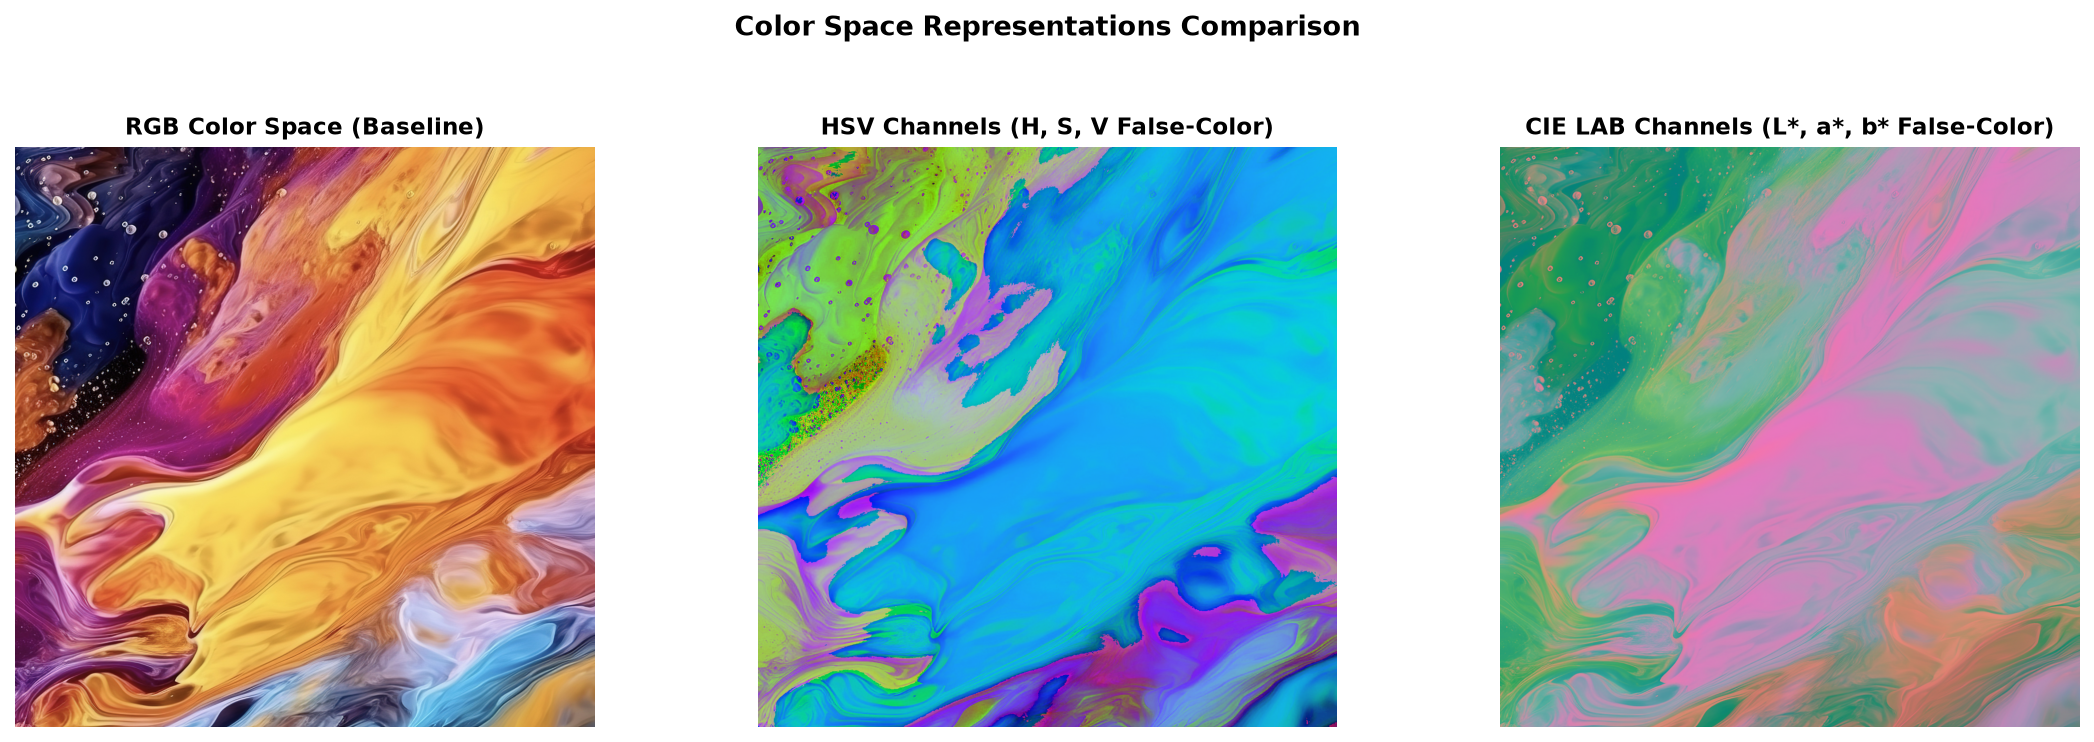

In [3]:
img_hsv = convert_color_space(img_rgb, source_space='RGB', target_space='HSV')
img_lab = convert_color_space(img_rgb, source_space='RGB', target_space='LAB')

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
panels = [
    (img_rgb, 'RGB Color Space (Baseline)'),
    (img_hsv, 'HSV Channels (H, S, V False-Color)'),
    (img_lab, 'CIE LAB Channels (L*, a*, b* False-Color)'),
]
for ax, (img, label) in zip(axes, panels):
    ax.imshow(img)
    ax.set_title(label, fontsize=11, fontweight='bold')
    ax.axis('off')
fig.suptitle('Color Space Representations Comparison', fontsize=13, fontweight='bold', y=0.98)
fig.tight_layout(rect=[0.0, 0.0, 1.0, 0.90])
show_figure(fig)

### 4. Thu nhỏ giữ tỷ lệ (Resize), Làm phẳng (Flatten) & Phân bố kênh màu RGB

Ảnh làm việc sau resize: 256 x 256 (65,536 pixels)
Ma trận điểm ảnh 2D: (65536, 3) | dtype=float32 | Số màu phân biệt: 53,450


,min,max,mean,std,median,iqr
R,3.0,253.0,177.27,67.88,203.0,92.0
G,2.0,245.0,118.06,62.87,121.0,106.0
B,2.0,247.0,92.18,46.13,83.0,47.0


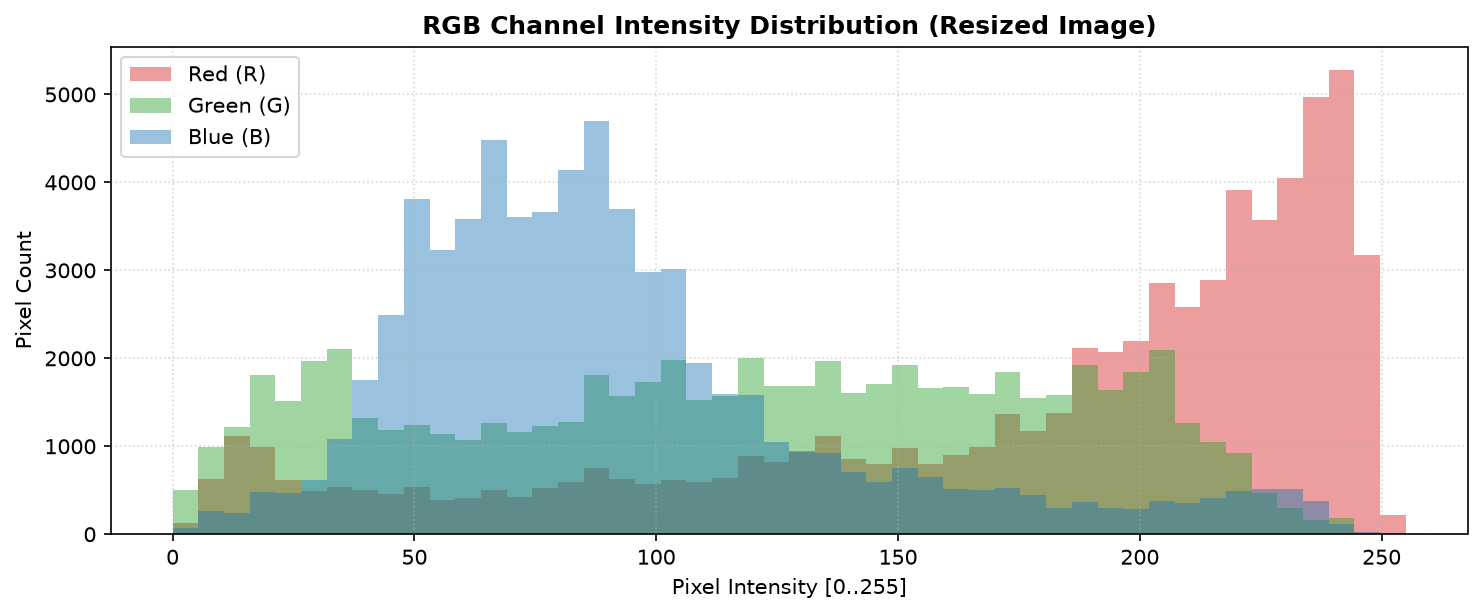

In [4]:
resized_rgb, (new_h, new_w) = resize_image(img_rgb, target_size=TARGET_SIZE, keep_aspect_ratio=True)
pixel_matrix = flatten_pixels(resized_rgb, as_float=True)
color_stats = compute_color_statistics(pixel_matrix)

print(f"Ảnh làm việc sau resize: {new_w} x {new_h} ({pixel_matrix.shape[0]:,} pixels)")
print(f"Ma trận điểm ảnh 2D: {pixel_matrix.shape} | dtype={pixel_matrix.dtype} | Số màu phân biệt: {color_stats['unique_colors']:,}")

df_channels = pd.DataFrame(color_stats['channels']).T
display(df_channels)

fig, ax = plt.subplots(figsize=(10, 4.2))
for idx, (ch_name, ch_color) in enumerate([('Red (R)', '#d62728'), ('Green (G)', '#2ca02c'), ('Blue (B)', '#1f77b4')]):
    ax.hist(pixel_matrix[:, idx], bins=48, range=(0, 255), alpha=0.45, color=ch_color, label=ch_name)
ax.set_title('RGB Channel Intensity Distribution (Resized Image)', fontsize=12, fontweight='bold')
ax.set_xlabel('Pixel Intensity [0..255]')
ax.set_ylabel('Pixel Count')
ax.grid(True, linestyle=':', alpha=0.5)
ax.legend()
fig.tight_layout()
show_figure(fig)